# Egg prices with gradient descent

A small Python experiment using the **original complete January 1980–April 2025 data**.
We fit a straight line to **log prices over the most recent 24 months** of each
fitting period, using gradient descent written with NumPy. Then we compare its
three-month forecasts with the naive baseline.

Gradient descent is the **optimization algorithm**; linear regression is the
**model**. This model learns a recent trend, with time as its only predictor.
The 24-month window is fixed in advance and is not selected using validation or
test results. It does not include an annual seasonal component.

Open this notebook from `analysis/` in the project and choose a Python 3 kernel.
Dependencies: `numpy`, `matplotlib`, and `ipykernel`.


In [1]:
from pathlib import Path
import csv
import hashlib
import os
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#172554', 'text.color': '#172554',
    'axes.titleweight': 'bold', 'font.size': 10,
})
COLORS = {'observed': '#172554', 'gd': '#2563eb', 'naive': '#b45309',
          'actual': '#0f766e'}

# Locate the project from either the repository root or analysis/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'APU0000708111.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the notebook inside the egg-onomics project.')
INPUT = ROOT / 'data' / 'APU0000708111.csv'
# Keep this experiment separate from the R outputs; override for a scratch run.
OUT = Path(os.environ.get('EGG_GD_OUTPUT', str(ROOT / 'results' / 'gradient_descent')))
OUT.mkdir(parents=True, exist_ok=True)

with INPUT.open(newline='', encoding='utf-8-sig') as handle:
    rows = list(csv.DictReader(handle))
dates = np.array([r['observation_date'] for r in rows], dtype='datetime64[M]')
prices = np.array([float(r['APU0000708111']) for r in rows])
month_index = np.arange(len(prices), dtype=float)
expected = np.arange(np.datetime64('1980-01', 'M'), np.datetime64('2025-05', 'M'))
assert len(prices) == 544 and np.array_equal(dates, expected)
assert np.isfinite(prices).all() and (prices > 0).all()
source_md5 = hashlib.md5(INPUT.read_bytes()).hexdigest()
assert source_md5 == 'bf246189cbf9d52a5da338e57f838d30'
print(f'{len(prices)} observed monthly prices: {dates[0]} to {dates[-1]}')
print('Missing months: 0. Missing prices: 0. No filling or interpolation.')


544 observed monthly prices: 1980-01 to 2025-04
Missing months: 0. Missing prices: 0. No filling or interpolation.


## Model and learning rule

Within each fitting window, standardize the month index using **only that window**:

\[
x_t = (t-\bar{t})/s_t, \qquad
\widehat{\log(P_t)} = \theta_0 + \theta_1 x_t.
\]

We minimize mean squared error on log prices:

\[
J(\theta)=\frac{1}{n}\|X\theta-y\|^2,
\qquad \nabla J(\theta)=\frac{2}{n}X^T(X\theta-y),
\qquad \theta\leftarrow\theta-\alpha\nabla J(\theta).
\]

The learning rate is 0.05. Training stops when the gradient is small, or after
5,000 updates. Exponentiating the fitted log trend gives positive **point
forecasts**. These are unadjusted back-transformed forecasts, not the
bias-adjusted dollar means used by the smoothing and ARIMA models in R.
This small experiment does not estimate prediction intervals.


In [2]:
LOOKBACK = 24
HORIZON = 3
LEARNING_RATE = 0.05
MAX_STEPS = 5000
TOLERANCE = 1e-10

def fit_gradient_descent(end):
    """Fit using observations before end; hold-out prices never enter training."""
    start = max(0, end - LOOKBACK)
    t = month_index[start:end]
    y = np.log(prices[start:end])
    center, scale = t.mean(), t.std()
    X = np.column_stack([np.ones(len(t)), (t - center) / scale])
    theta = np.zeros(2)
    loss = [float(np.mean((X @ theta - y) ** 2))]
    for step in range(1, MAX_STEPS + 1):
        gradient = 2 * X.T @ (X @ theta - y) / len(y)
        theta -= LEARNING_RATE * gradient
        loss.append(float(np.mean((X @ theta - y) ** 2)))
        if np.linalg.norm(gradient) < TOLERANCE:
            break

    # Independent numerical check: GD should reach the least-squares solution.
    exact_theta = np.linalg.lstsq(X, y, rcond=None)[0]
    assert np.allclose(theta, exact_theta, atol=1e-7, rtol=0)
    assert np.all(np.diff(loss) <= 1e-12), 'Loss should not increase.'
    assert step < MAX_STEPS, 'Optimizer did not converge.'
    return dict(theta=theta, center=center, scale=scale, loss=np.array(loss),
                steps=step, start=start, end=end)

def predict(model, t):
    t = np.asarray(t, dtype=float)
    X = np.column_stack([np.ones(len(t)), (t - model['center']) / model['scale']])
    return np.exp(X @ model['theta'])

def score(actual, forecast):
    error = actual - forecast
    return dict(MAE=float(np.mean(np.abs(error))),
                RMSE=float(np.sqrt(np.mean(error ** 2))),
                MAPE=float(100 * np.mean(np.abs(error / actual))))


## Three-month evaluation

The fitting origins match the R experiment:

| Stage | Available history ends | Forecast months |
| --- | --- | --- |
| Validation | October 2024 | November 2024–January 2025 |
| Test | January 2025 | February–April 2025 |
| Historical future forecast | April 2025 | May–July 2025 |

At each origin, the gradient-descent model uses only the latest 24 available
months. The naive forecast repeats the last available price. Each forecast is
issued once for all three months, without updating inside the hold-out period.
The forecast settings stay fixed across stages; neither validation nor test
prices are used to choose this demonstration's settings.


In [3]:
origins = {'Validation': len(prices) - 6, 'Test': len(prices) - 3,
           'Future': len(prices)}
experiments, accuracy_rows, prediction_rows = {}, [], []
for stage, end in origins.items():
    model = fit_gradient_descent(end)
    future_t = np.arange(end, end + HORIZON)
    future_dates = dates[end - 1] + np.arange(1, HORIZON + 1).astype('timedelta64[M]')
    forecasts = {'Gradient descent': predict(model, future_t),
                 'Naive': np.repeat(prices[end - 1], HORIZON)}
    actual = prices[end:end + HORIZON] if stage != 'Future' else None
    experiments[stage] = dict(model=model, dates=future_dates,
                              forecasts=forecasts, actual=actual)
    for method, forecast in forecasts.items():
        if actual is not None:
            accuracy_rows.append(dict(stage=stage, model=method, **score(actual, forecast)))
        for j, date in enumerate(future_dates):
            prediction_rows.append(dict(stage=stage, model=method, date=str(date),
                forecast=float(forecast[j]), actual='' if actual is None else float(actual[j])))

print(f"{'Stage':<12} {'Model':<18} {'MAE':>8} {'RMSE':>8} {'MAPE %':>9}")
for row in accuracy_rows:
    print(f"{row['stage']:<12} {row['model']:<18} {row['MAE']:8.3f} "
          f"{row['RMSE']:8.3f} {row['MAPE']:9.2f}")
for stage in ['Validation', 'Test']:
    scores = {r['model']: r['RMSE'] for r in accuracy_rows if r['stage'] == stage}
    winner = min(scores, key=scores.get)
    print(f'{stage}: {winner} has lower RMSE in this three-month window.')
print('\nHistorical forecasts from April 2025, dollars per dozen:')
for date, gd, naive in zip(experiments['Future']['dates'],
                          experiments['Future']['forecasts']['Gradient descent'],
                          experiments['Future']['forecasts']['Naive']):
    print(f'{date}: GD ${gd:.3f}; naive ${naive:.3f}')


Stage        Model                   MAE     RMSE    MAPE %
Validation   Gradient descent      1.599    1.692     36.61
Validation   Naive                 0.879    1.031     19.44
Test         Gradient descent      2.117    2.175     36.34
Test         Naive                 0.796    0.921     13.26
Validation: Naive has lower RMSE in this three-month window.
Test: Naive has lower RMSE in this three-month window.

Historical forecasts from April 2025, dollars per dozen:
2025-05: GD $5.273; naive $5.122
2025-06: GD $5.506; naive $5.122
2025-07: GD $5.749; naive $5.122


## Learning curve and forecast plots

The loss curve shows whether the optimizer converges. It does not measure
forecast accuracy. In the other panels, both forecast lines connect to the last
observed price, and validation/test actuals are shown separately.


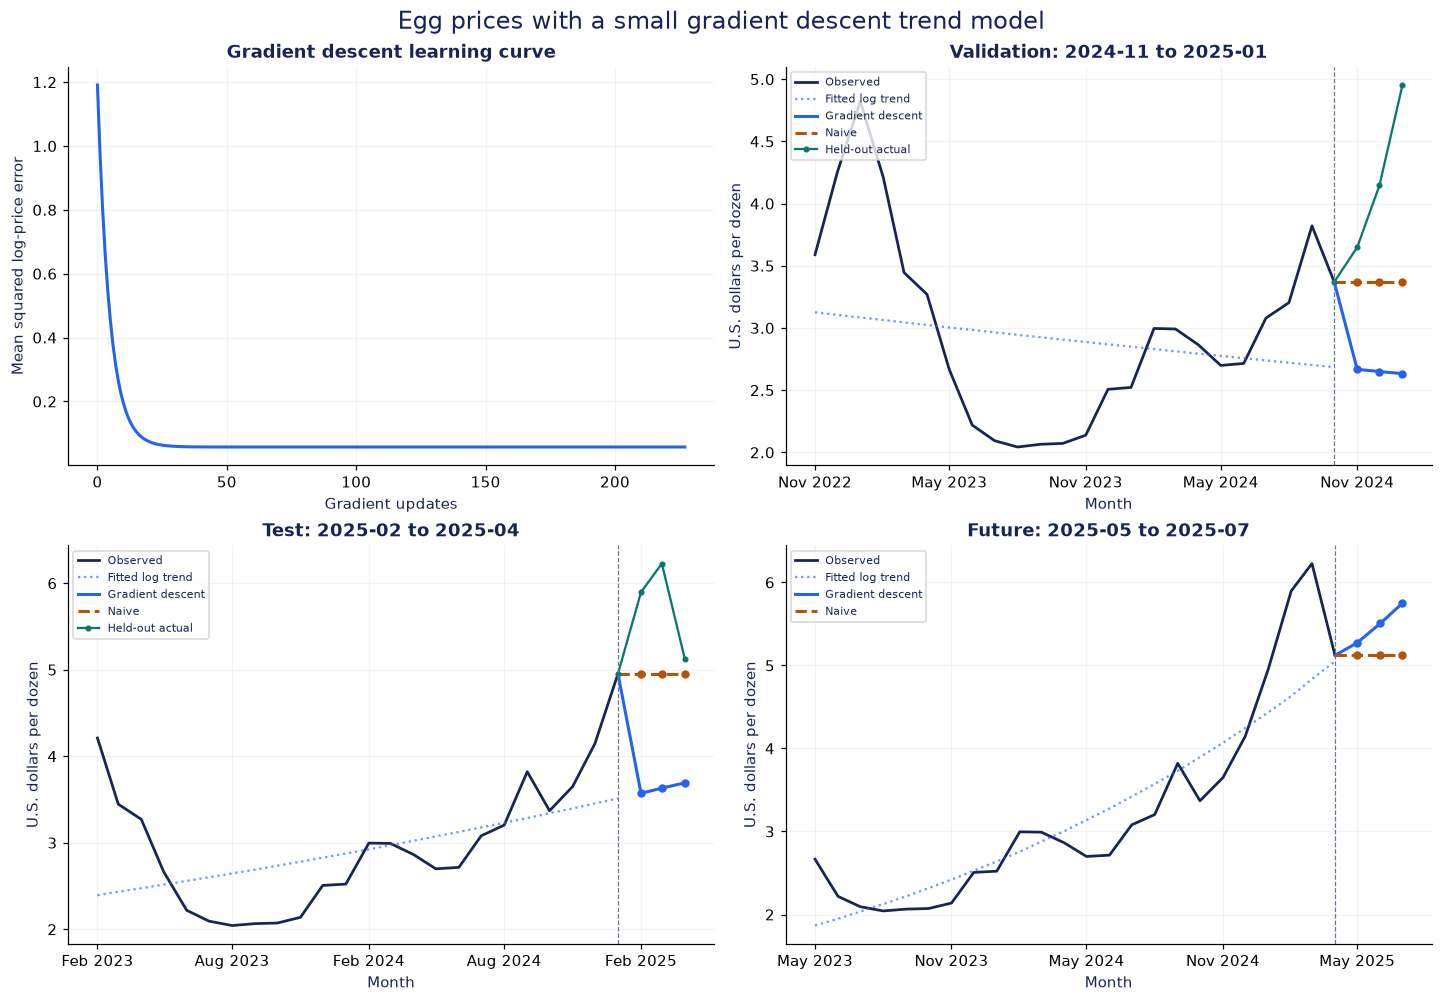

In [4]:
def draw_forecast(ax, stage):
    result = experiments[stage]
    model = result['model']
    end = model['end']
    past = slice(model['start'], end)
    known_dates = dates[past].astype('datetime64[D]')
    next_dates = result['dates'].astype('datetime64[D]')
    origin_date = dates[end - 1].astype('datetime64[D]')
    joined_dates = np.concatenate([[origin_date], next_dates])
    ax.plot(known_dates, prices[past], color=COLORS['observed'], label='Observed', lw=1.8)
    ax.plot(known_dates, predict(model, month_index[past]), color=COLORS['gd'],
            ls=':', alpha=0.65, label='Fitted log trend')
    for method, color, style in [('Gradient descent', COLORS['gd'], '-'),
                                 ('Naive', COLORS['naive'], '--')]:
        forecast = result['forecasts'][method]
        ax.plot(joined_dates, np.r_[prices[end - 1], forecast],
                color=color, ls=style, label=method, lw=2)
        ax.scatter(next_dates, forecast, color=color, s=20, zorder=3)
    if result['actual'] is not None:
        ax.plot(joined_dates, np.r_[prices[end - 1], result['actual']],
                color=COLORS['actual'], label='Held-out actual', marker='o', ms=3)
    ax.axvline(origin_date, color='#64748b', ls='--', lw=0.8)
    ax.set(title=f"{stage}: {result['dates'][0]} to {result['dates'][-1]}",
           ylabel='U.S. dollars per dozen', xlabel='Month')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=7, loc='upper left')

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
loss = experiments['Validation']['model']['loss']
axes[0, 0].plot(np.arange(len(loss)), loss, color=COLORS['gd'], lw=2)
axes[0, 0].set(title='Gradient descent learning curve', xlabel='Gradient updates',
               ylabel='Mean squared log-price error')
axes[0, 0].grid(alpha=0.15)
for ax, stage in zip([axes[0, 1], axes[1, 0], axes[1, 1]], origins):
    draw_forecast(ax, stage)
fig.suptitle('Egg prices with a small gradient descent trend model', fontsize=16)
fig.savefig(OUT / 'gradient_descent_comparison.png', dpi=160, bbox_inches='tight')
plt.show()


## Reading the results

Compare hold-out RMSE and MAE with the naive baseline: lower is better. A model
can converge perfectly during training and still forecast poorly. This simple
trend cannot anticipate supply shocks or changes in direction, and it has no
predictors besides time. Three test observations are too few to establish stable
performance. May–July 2025 are historical forecasts from the saved April 2025
snapshot, not forecasts for the current date.

The checks below verify that both evaluation periods match the R analysis and
that every fit ends before its forecast months. The experiment writes its own
tables and plot into `results/gradient_descent/`.


In [5]:
assert [str(d) for d in experiments['Validation']['dates']] == ['2024-11', '2024-12', '2025-01']
assert [str(d) for d in experiments['Test']['dates']] == ['2025-02', '2025-03', '2025-04']
assert [str(d) for d in experiments['Future']['dates']] == ['2025-05', '2025-06', '2025-07']
for stage, result in experiments.items():
    model = result['model']
    assert dates[model['end'] - 1] < result['dates'][0]
    assert model['end'] - model['start'] == LOOKBACK

def save_csv(filename, rows):
    with (OUT / filename).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

save_csv('accuracy.csv', accuracy_rows)
save_csv('predictions.csv', prediction_rows)
fit_rows = []
for stage, result in experiments.items():
    model = result['model']
    slope_per_month = model['theta'][1] / model['scale']
    fit_rows.append(dict(stage=stage, fit_start=str(dates[model['start']]),
        fit_end=str(dates[model['end'] - 1]), observations=LOOKBACK,
        steps=model['steps'], initial_loss=model['loss'][0], final_loss=model['loss'][-1],
        intercept_standardized=model['theta'][0], slope_standardized=model['theta'][1],
        slope_log_per_month=slope_per_month,
        implied_monthly_change_percent=100 * np.expm1(slope_per_month)))
save_csv('fits.csv', fit_rows)
save_csv('validation_learning_curve.csv',
         [dict(step=i, loss=float(value)) for i, value in enumerate(loss)])
(OUT / 'run_info.txt').write_text(
    f'Python {platform.python_version()}\nNumPy {np.__version__}\n'
    f'Matplotlib {matplotlib.__version__}\nSource MD5 {source_md5}\n'
    f'Lookback {LOOKBACK}; horizon {HORIZON}; learning rate {LEARNING_RATE}\n'
    'Unadjusted exp(log-trend) point forecasts; no prediction intervals.\n',
    encoding='utf-8')
print('Checks passed: original complete data, correct dates, no hold-out leakage,')
print('decreasing training loss, and agreement with the least-squares optimum.')
print(f'Outputs saved to {OUT}')


Checks passed: original complete data, correct dates, no hold-out leakage,
decreasing training loss, and agreement with the least-squares optimum.
Outputs saved to c:\Users\Kelvin\Desktop\Folders\GitHub\egg-onomics\results\gradient_descent
